# 파트 A. 국민건강영양조사 제7기(2016–2018) 류마티스관절염 관련 요인 탐색

**연구 질문**: 류마티스관절염 의사진단자는 흡연, 비만, 전신 염증(hs-CRP)과 어떤 관련이 있는가? 이 변수들로 진단 여부를 얼마나 구분할 수 있는가?

**변수 정의 근거**: 국민건강영양조사 제7기(2016–2018) 원시자료 이용지침서

| 변수 | 원자료 | 지침서 정의 |
|---|---|---|
| 결과 | `DM3_dg` | 류마티스성 관절염 의사진단 여부 (0 없음, 1 있음, 8 비해당(청소년·소아), 9 모름) |
| 흡연 | `BS1_1`, `BS3_1` | 현재흡연 = 평생 5갑 이상(`BS1_1`=2) & 현재 매일/가끔(`BS3_1`=1,2) — 지침서 주요지표 정의 |
| 음주 | `BD1`, `BD1_11` | 1년간 음주빈도 1~6, **8 = 비해당(평생 비음주)** → '최근 1년 안 마심'(1)으로 처리 |
| 염증 | `HE_hsCRP`, `HE_hsCRP_etc` | 2017–18: 0.15 mg/L 미만 `<0.15`, 20 mg/L 초과 `>20.00` 별도 표기 |
| 교육·소득 | `edu`, `ho_incm` | 1~4 범주 |
| 가중치 | `wt_itvex` | 건강설문-검진조사 가중치. 3개년 통합 시 조사구수 비율(각 1/3) 곱함 |

> 이 노트북은 2018년 파일 하나로도 돌아가고, 2016·2017 파일을 같은 폴더에 넣으면 자동으로 합칩니다.

In [1]:
# Colab에서 처음 한 번만 실행
!pip install -q lightgbm shap statsmodels

In [2]:
import glob, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.formula.api as smf
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve, precision_recall_curve
import lightgbm as lgb
import shap

RANDOM_STATE = 42
pd.set_option("display.max_columns", 50)

## 1. 데이터 불러오기
`hn16_all.sas7bdat`, `hn17_all.sas7bdat`, `hn18_all.sas7bdat` 중 있는 파일을 모두 읽습니다. 836개 변수 중 필요한 것만 남겨 메모리를 아낍니다.

In [5]:
KEEP = ["ID", "year", "age", "sex", "psu", "kstrata", "wt_itvex",
        "DM3_dg", "DM3_pr", "DM3_pt",
        "BS1_1", "BS3_1", "BD1", "BD1_11",
        "HE_BMI", "HE_hsCRP", "HE_hsCRP_etc", "HE_WBC", "HE_HB",
        "edu", "ho_incm"]

files = sorted(glob.glob("hn1[678]_all*.sas7bdat"))
print("읽을 파일:", files)

frames = []
for f in files:
    d = pd.read_sas(f, encoding="latin1")
    frames.append(d[[c for c in KEEP if c in d.columns]])
raw = pd.concat(frames, ignore_index=True).drop_duplicates("ID")
print(raw.shape)
raw["year"].value_counts().sort_index()

읽을 파일: ['hn18_all.sas7bdat']
(7992, 21)


,count
year,
2018.0,7992


## 2. 전처리 (지침서 코드 기준)

In [6]:
df = raw.copy()

# (1) 대상: 성인, 류마티스관절염 문항에 0/1로 응답한 사람
df = df[(df["age"] >= 19) & df["DM3_dg"].isin([0, 1])].copy()
df["ra"] = df["DM3_dg"].astype(int)
df["female"] = (df["sex"] == 2).astype(int)

# (2) hs-CRP: 장비 분석범위 밖 값 채우기
etc = df["HE_hsCRP_etc"].astype(str).str.strip()
df.loc[etc == "<0.15", "HE_hsCRP"] = 0.075        # 검출하한(0.15)의 절반
df.loc[etc == ">20.00", "HE_hsCRP"] = 20.01       # 2016년은 원자료에 이미 20.01로 표기
df["log_crp"] = np.log(df["HE_hsCRP"])
df["crp_high"] = (df["HE_hsCRP"] > 3).astype(float).where(df["HE_hsCRP"].notna())  # >3 mg/L: 고위험 염증

# (3) 흡연 상태 (지침서 현재흡연율 정의)
def smoking(r):
    if r["BS1_1"] in (1, 3):                     # 평생 5갑 미만 또는 피운 적 없음
        return "never"
    if r["BS1_1"] == 2 and r["BS3_1"] in (1, 2):
        return "current"
    if r["BS1_1"] == 2 and r["BS3_1"] == 3:
        return "former"
    return np.nan                                 # 9 모름 등
df["smoke"] = df.apply(smoking, axis=1)

# (4) 음주 빈도: 8(평생 비음주)은 1(최근 1년 안 마심)로, 9는 결측
df["alcohol"] = df["BD1_11"].replace({8: 1, 9: np.nan})
df["drink_month"] = (df["alcohol"] >= 3).astype(float).where(df["alcohol"].notna())  # 월 1회 이상

# (5) 비만, 교육, 소득
df["obese"] = (df["HE_BMI"] >= 25).astype(float).where(df["HE_BMI"].notna())  # 국내 비만 기준
df["edu"] = df["edu"].where(df["edu"].isin([1, 2, 3, 4]))
df["income"] = df["ho_incm"].where(df["ho_incm"].isin([1, 2, 3, 4]))

# (6) 3개년 통합 가중치 (연도별 조사구수 동일 → 1/연도수)
df["wt_pool"] = df["wt_itvex"] / df["year"].nunique()

print(f"성인 {len(df):,}명 | 류마티스관절염 진단 {df.ra.sum()}명 ({df.ra.mean():.2%})")
print(df["smoke"].value_counts(dropna=False))
df[["HE_hsCRP", "HE_BMI", "alcohol"]].describe().round(2)

성인 5,990명 | 류마티스관절염 진단 112명 (1.87%)
smoke
never      3709
former     1195
current    1073
NaN          13
Name: count, dtype: int64


,HE_hsCRP,HE_BMI,alcohol
count,5817.00,5946.00,5980.00
mean,1.13,23.98,3.01
std,2.21,3.55,1.66
min,0.08,14.66,1.00
25%,0.25,21.52,1.00
50%,0.46,23.64,3.00
75%,0.99,26.01,4.00
max,20.01,44.48,6.00


## 3. 기술통계: 진단군 vs 비진단군
진단군은 나이가 많고 여성이 많을 것으로 예상됩니다. 그래서 이후 분석에서 나이·성별 보정이 꼭 필요합니다.

In [7]:
# 연속형: Welch t-검정 (CRP는 로그 변환값으로 검정, 표시는 중앙값)
rows = []
for c in ["age", "HE_BMI", "log_crp", "HE_WBC", "HE_HB"]:
    a, b = df.loc[df.ra == 1, c].dropna(), df.loc[df.ra == 0, c].dropna()
    p = stats.ttest_ind(a, b, equal_var=False).pvalue
    rows.append([c, f"{a.mean():.2f}", f"{b.mean():.2f}", f"{p:.3g}"])
print(pd.DataFrame(rows, columns=["변수", "진단", "비진단", "p"]).to_string(index=False))
print("hs-CRP 중앙값(mg/L): 진단", df.loc[df.ra==1,'HE_hsCRP'].median(), "| 비진단", df.loc[df.ra==0,'HE_hsCRP'].median())

# 범주형: 카이제곱 검정
for c in ["female", "smoke", "obese", "crp_high", "drink_month", "edu", "income"]:
    tab = pd.crosstab(df[c], df["ra"])
    p = stats.chi2_contingency(tab)[1]
    pct = pd.crosstab(df[c], df["ra"], normalize="columns").mul(100).round(1)
    print(f"\n[{c}] p={p:.3g}"); print(pct.rename(columns={0: "비진단%", 1: "진단%"}))

     변수    진단   비진단        p
    age 63.21 51.32 2.81e-13
 HE_BMI 23.82 23.98    0.623
log_crp -0.32 -0.65   0.0116
 HE_WBC  5.77  6.14   0.0177
  HE_HB 13.29 14.09 4.95e-08
hs-CRP 중앙값(mg/L): 진단 0.6 | 비진단 0.46

[female] p=1.09e-06
ra      비진단%   진단%
female            
0       44.0  20.5
1       56.0  79.5

[smoke] p=0.0033
ra       비진단%   진단%
smoke              
current  18.1  10.8
former   20.2  11.7
never    61.8  77.5

[obese] p=0.659
ra     비진단%   진단%
obese            
0.0    65.2  62.7
1.0    34.8  37.3

[crp_high] p=0.17
ra        비진단%   진단%
crp_high            
0.0       92.0  87.9
1.0        8.0  12.1

[drink_month] p=8.89e-06
ra           비진단%   진단%
drink_month            
0.0          45.9  67.6
1.0          54.1  32.4

[edu] p=2.42e-11
ra   비진단%   진단%
edu            
1.0  19.0  39.1
2.0   9.8  20.0
3.0  33.5  28.2
4.0  37.6  12.7

[income] p=3.32e-08
ra      비진단%   진단%
income            
1.0     18.5  41.1
2.0     24.2  21.4
3.0     27.5  18.8
4.0     29.8  18.8


In [8]:
# 가중 유병률 (모집단 추정)
w = df["wt_pool"]
print(f"가중 유병률: {np.average(df.ra, weights=w):.2%}")
for s, name in [(0, "남성"), (1, "여성")]:
    m = df.female == s
    print(f"  {name}: {np.average(df.ra[m], weights=w[m]):.2%}")
# ※ 표준오차·신뢰구간까지 정확히 내려면 층(kstrata)·집락(psu)을 반영한 복합표본 분석 필요
#   (R survey 패키지 또는 SAS PROC SURVEYLOGISTIC)

가중 유병률: 1.50%
  남성: 0.73%
  여성: 2.25%


## 4. 로지스틱 회귀
- 모델 1: 나이·성별만 보정
- 모델 2: + 흡연, BMI, 음주, 교육, 소득
- 모델 3: + hs-CRP

흡연 기준범주는 비흡연(never)입니다.

In [9]:
base = "ra ~ age + female"
m2 = base + " + C(smoke, Treatment('never')) + HE_BMI + alcohol + C(edu) + C(income)"
m3 = m2 + " + log_crp"
need = ["smoke", "HE_BMI", "alcohol", "edu", "income", "log_crp"]
cc = df.dropna(subset=need)          # 세 모델을 같은 사람으로 비교
print("완전자료:", len(cc), "| 진단", cc.ra.sum())

def or_table(fit):
    t = pd.concat([np.exp(fit.params), np.exp(fit.conf_int()), fit.pvalues], axis=1)
    t.columns = ["OR", "95%CI_low", "95%CI_high", "p"]
    return t.drop("Intercept").round(3)

fits = {}
for name, f in [("모델1", base), ("모델2", m2), ("모델3", m3)]:
    fits[name] = smf.logit(f, data=cc).fit(disp=0)
    print(f"\n===== {name} (AIC {fits[name].aic:.1f}) =====")
    print(or_table(fits[name]))

완전자료: 5730 | 진단 103

===== 모델1 (AIC 956.9) =====
           OR  95%CI_low  95%CI_high    p
age     1.051      1.037       1.066  0.0
female  2.872      1.784       4.622  0.0

===== 모델2 (AIC 963.3) =====
                                            OR  95%CI_low  95%CI_high      p
C(smoke, Treatment('never'))[T.current]  1.353      0.639       2.864  0.429
C(smoke, Treatment('never'))[T.former]   0.992      0.456       2.157  0.984
C(edu)[T.2.0]                            1.557      0.872       2.779  0.134
C(edu)[T.3.0]                            1.168      0.629       2.167  0.623
C(edu)[T.4.0]                            0.596      0.264       1.345  0.213
C(income)[T.2.0]                         0.624      0.358       1.085  0.095
C(income)[T.3.0]                         0.635      0.350       1.154  0.136
C(income)[T.4.0]                         0.642      0.341       1.208  0.170
age                                      1.039      1.019       1.060  0.000
female                    

In [10]:
# 성별 층화 (여성 환자가 대부분이라 남성 결과는 불안정할 수 있음)
for s, name in [(0, "남성"), (1, "여성")]:
    sub = cc[cc.female == s]
    f = smf.logit("ra ~ age + C(smoke, Treatment('never')) + HE_BMI + log_crp", data=sub).fit(disp=0)
    print(f"\n[{name}] n={len(sub)}, 진단={sub.ra.sum()}"); print(or_table(f))


[남성] n=2521, 진단=22
                                            OR  95%CI_low  95%CI_high      p
C(smoke, Treatment('never'))[T.current]  3.260      0.700      15.193  0.132
C(smoke, Treatment('never'))[T.former]   2.814      0.601      13.168  0.189
age                                      1.021      0.992       1.052  0.162
HE_BMI                                   0.936      0.814       1.075  0.349
log_crp                                  1.192      0.822       1.729  0.354

[여성] n=3209, 진단=81
                                            OR  95%CI_low  95%CI_high      p
C(smoke, Treatment('never'))[T.current]  1.023      0.313       3.341  0.971
C(smoke, Treatment('never'))[T.former]   0.753      0.181       3.139  0.697
age                                      1.058      1.041       1.077  0.000
HE_BMI                                   0.952      0.887       1.022  0.177
log_crp                                  1.264      1.045       1.530  0.016


## 5. 머신러닝 비교
- 전처리(결측 대치·표준화)는 Pipeline 안에서 → 교차검증 폴드마다 따로 학습되어 **데이터 누수 방지**
- 진단 비율이 2% 정도인 **불균형 자료**라 AUROC와 함께 AUPRC를 봅니다. AUPRC의 무작위 기준선은 유병률입니다.

In [11]:
X = pd.get_dummies(df[["age", "female", "HE_BMI", "alcohol", "edu", "income",
                       "log_crp", "HE_WBC", "HE_HB", "smoke"]],
                   columns=["smoke"], dtype=float)          # 흡연 → current/former/never 더미
y = df["ra"]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

models = {
    "Logistic": Pipeline([("imp", SimpleImputer(strategy="median")),
                          ("sc", StandardScaler()),
                          ("lr", LogisticRegression(class_weight="balanced", max_iter=2000))]),
    "LightGBM": lgb.LGBMClassifier(n_estimators=300, learning_rate=0.03, num_leaves=7,
                                   min_child_samples=30, class_weight="balanced",
                                   random_state=RANDOM_STATE, verbose=-1),
}
pred = {}
for name, m in models.items():
    pred[name] = cross_val_predict(m, X, y, cv=cv, method="predict_proba")[:, 1]
    print(f"{name:9s} AUROC={roc_auc_score(y, pred[name]):.3f} | "
          f"AUPRC={average_precision_score(y, pred[name]):.3f} (기준선 {y.mean():.3f})")

# 나이·성별만 쓴 기준 모델: 다른 변수가 더해주는 정보가 있는지 확인
p0 = cross_val_predict(models["Logistic"], X[["age", "female"]], y, cv=cv, method="predict_proba")[:, 1]
print(f"나이+성별만 AUROC={roc_auc_score(y, p0):.3f} | AUPRC={average_precision_score(y, p0):.3f}")

Logistic  AUROC=0.732 | AUPRC=0.049 (기준선 0.019)
LightGBM  AUROC=0.713 | AUPRC=0.066 (기준선 0.019)
나이+성별만 AUROC=0.733 | AUPRC=0.052


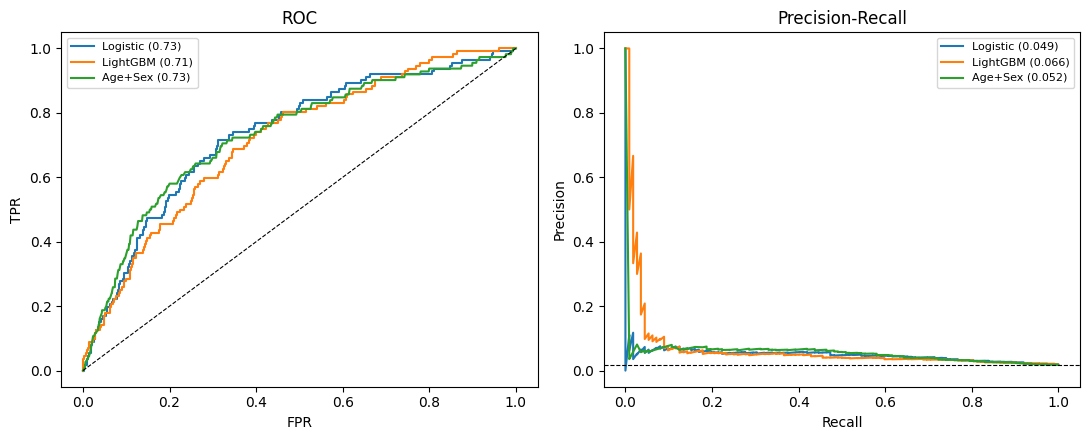

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
for name, p in list(pred.items()) + [("Age+Sex", p0)]:
    fpr, tpr, _ = roc_curve(y, p); ax[0].plot(fpr, tpr, label=f"{name} ({roc_auc_score(y, p):.2f})")
    pr, rc, _ = precision_recall_curve(y, p); ax[1].plot(rc, pr, label=f"{name} ({average_precision_score(y, p):.3f})")
ax[0].plot([0, 1], [0, 1], "k--", lw=.8); ax[0].set(xlabel="FPR", ylabel="TPR", title="ROC")
ax[1].axhline(y.mean(), color="k", ls="--", lw=.8); ax[1].set(xlabel="Recall", ylabel="Precision", title="Precision-Recall")
for a in ax: a.legend(fontsize=8)
plt.tight_layout(); plt.savefig("roc_pr.png", dpi=150); plt.show()

## 6. SHAP 해석
SHAP은 **모델 예측에 대한 기여도**이지 인과 효과가 아닙니다. 예를 들어 CRP가 높게 기여하더라도, 질환 때문에 염증이 올라간 것(역인과)일 수 있습니다.

/usr/local/lib/python3.13/dist-packages/shap/explainers/_tree.py:578: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


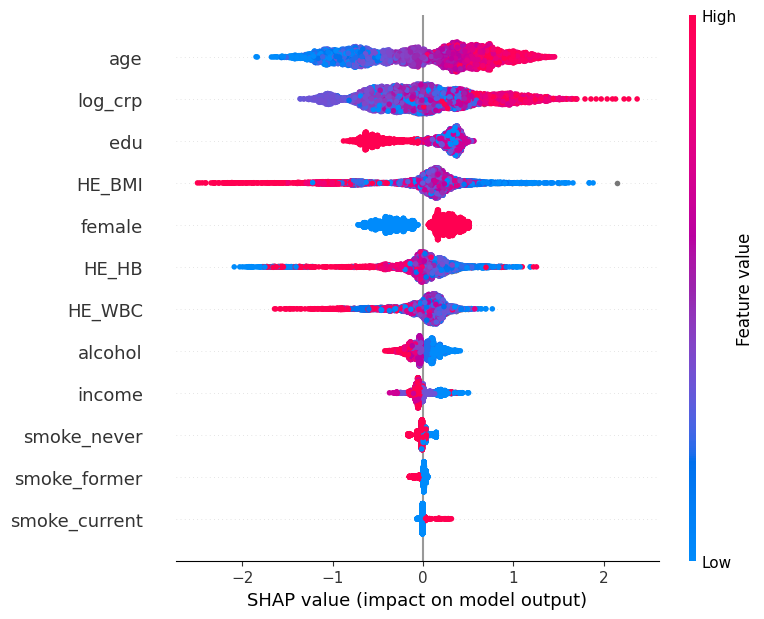

In [13]:
gbm = models["LightGBM"].fit(X, y)
sv = shap.TreeExplainer(gbm).shap_values(X)
sv = sv[1] if isinstance(sv, list) else sv
shap.summary_plot(sv, X, show=False)
plt.tight_layout(); plt.savefig("shap_summary.png", dpi=150); plt.show()

## 7. 한계와 다음 단계
- **단면 자료**: 진단 후 금연·체중 변화·치료(스테로이드, 항류마티스제)가 섞여 있어 역인과 가능. `DM3_pt`(치료 여부)로 민감도 분석 가능
- **자가보고 진단**: 골관절염과 혼동하는 오분류 가능 → 실제 유병률보다 높게 나올 수 있음
- **표본 수**: 한 해 진단자 약 110명 → 3개년 통합 권장, 남성 층화 결과는 불안정
- **복합표본 설계**: 회귀·ML은 가중치 없이 수행(연관성·예측 비교 목적). 모집단 추정치는 층·집락·가중치 반영 필요
- **CRP 하한 대치**: 0.15 미만을 0.075로 둔 선택에 대한 민감도 분석(예: 0.15로 대치) 권장

→ 흡연·BMI가 류마티스관절염의 **원인**인지는 파트 B(2표본 멘델리안 무작위분석)로 확인